# Tópicos em Ciência de Dados

_Especialização em Inteligência Artiﬁcial_

_Professor: Petrus Abreu_

## Módulo 1 — Introdução à Análise Exploratória de Dados

### Lista de Exercícios

**Aluna: Angelina de Meiras Ottoni**

In [81]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [83]:
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'

In [84]:
df = pd.read_csv(url)

In [85]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [86]:
df.shape

(1338, 7)

In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


## Questão 1 – Fundamentos e Estrutura de Dados

### Item a

In [88]:
# Valores únicos
print(df['smoker'].unique())

<StringArray>
['yes', 'no']
Length: 2, dtype: str


In [89]:
# Contagem de cada categoria
print(df['smoker'].value_counts())

smoker
no     1064
yes     274
Name: count, dtype: int64


In [90]:
# Frequência relativa (%)
print(df['smoker'].value_counts(normalize=True) * 100)


smoker
no     79.521674
yes    20.478326
Name: proportion, dtype: float64


>A variável smoker assume apenas as categorias 'yes' e 'no', que representam grupos sem ordem natural. Portanto, trata-se de uma variável qualitativa (categórica) nominal.

Alternativa correta: (B) Qualitativa nominal, pois representa categorias sem ordem natural.

### Item b

In [91]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Alternativa correta: (D) Estatísticas descritivas (contagem, média, desvio padrão, quartis) para todas
as variáveis numéricas.

### Item c

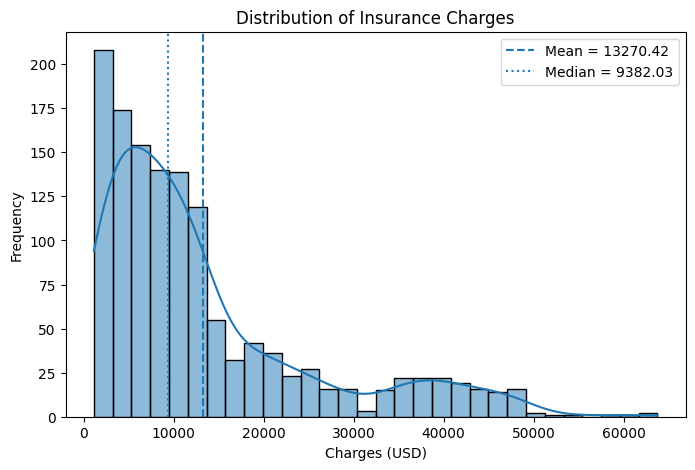

In [92]:
mean_charges = df['charges'].mean()
median_charges = df['charges'].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='charges',
    bins=30,
    kde=True
)

plt.axvline(
    mean_charges,
    linestyle='--',
    label=f'Mean = {mean_charges:.2f}'
)

plt.axvline(
    median_charges,
    linestyle=':',
    label=f'Median = {median_charges:.2f}'
)

plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges (USD)')
plt.ylabel('Frequency')
plt.legend()

plt.show()

Temos:

Média = 13.270,42   
Mediana = 9.382,03

Quando:

`Média > Mediana`

a distribuição apresenta cauda à direita.

Isso acontece porque alguns custos muito altos "puxam" a média.

>Alternativa correta: (C) A média é maior que a mediana, pois é puxada pelos valores extremos elevados.

### Item d

O coeficiente de Pearson varia entre:

`-1 ≤ r ≤ 1` 

onde:

-1 → correlação negativa perfeita   
0 → sem correlação linear   
+1 → correlação positiva perfeita   

>Alternativa correta: (C) [-1,1], sendo −1 correlação negativa perfeita e +1 correlação positiva perfeita.

## Questão 2 – Análise de Resultados: Estatística Descritiva

### Item a

In [93]:
print(df['charges'].describe().round(2))

count     1338.00
mean     13270.42
std      12110.01
min       1121.87
25%       4740.29
50%       9382.03
75%      16639.91
max      63770.43
Name: charges, dtype: float64


**Resposta**

>A distribuição é assimétrica à direita (positivamente assimétrica), pois a média (13.270,42) é maior que a mediana (9.382,03). Isso indica a presença de valores elevados que puxam a média para cima.

### Item b — Coeficiente de Variação

In [94]:
# Calcula o CV
mean_charges = df['charges'].mean()
std_charges = df['charges'].std()

cv_charges = (std_charges / mean_charges) * 100

print(f'Mean: {mean_charges:.2f}')
print(f'Standard Deviation: {std_charges:.2f}')
print(f'Coefficient of Variation: {cv_charges:.2f}%')

Mean: 13270.42
Standard Deviation: 12110.01
Coefficient of Variation: 91.26%


**Resposta**

>O coeficiente de variação da variável `charges` é aproximadamente 91,26%. Como o CV é muito elevado, os custos do seguro apresentam alta dispersão em relação à média, caracterizando uma distribuição heterogênea. Isso indica grande variabilidade entre os segurados quanto aos custos cobrados.

### Item c

**Resposta**

>Eu utilizaria a mediana, pois ela representa melhor o custo típico do segurado. A média é fortemente influenciada pelos custos extremamente elevados presentes na distribuição.

## Questão 3 – Código Python: Análise Bivariada

### Item a

In [95]:
# Código 2 Análise bivariada: IMC vs. custo do seguro por hábito de fumar.
df_smokers = df[df['smoker'] == 'yes']
df_non_smokers = df[df['smoker'] == 'no']

In [96]:
# (a-i) Calcule a correlacao de Pearson entre 'bmi' e 'charges'
correlation = df['bmi'].corr(df['charges'])

print(f"Correlação entre IMC e Custo: {correlation:.4f}")

Correlação entre IMC e Custo: 0.1983


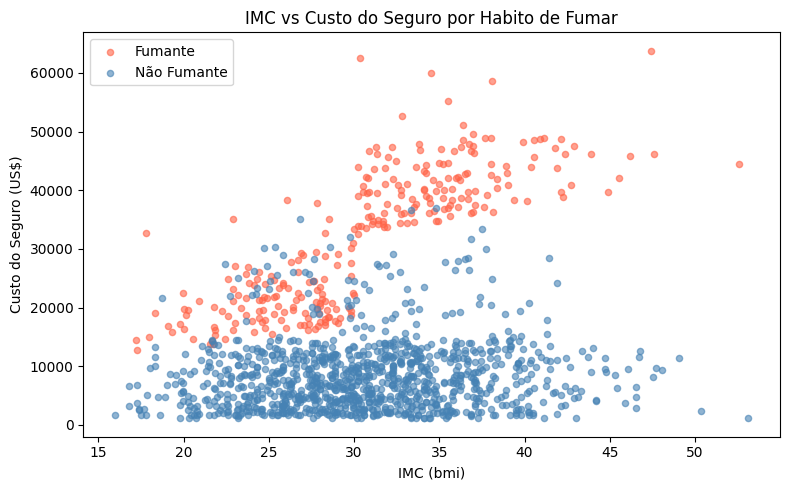

In [97]:
# (a-ii) Complete o scatter plot

plt.figure(figsize=(8, 5))

plt.scatter(
    df_smokers['bmi'],
    df_smokers['charges'],
    label='Fumante',
    alpha=0.6,
    color='tomato',
    s=20
)

plt.scatter(
    df_non_smokers['bmi'],
    df_non_smokers['charges'],
    label='Não Fumante',
    alpha=0.6,
    color='steelblue',
    s=20
)

plt.xlabel("IMC (bmi)")
plt.ylabel("Custo do Seguro (US$)")
plt.title("IMC vs Custo do Seguro por Habito de Fumar")
plt.legend()
plt.tight_layout()
plt.show()

### Item b

**Resposta**

>A correlação é positiva e fraca. Isso indica que custos tendem a aumentar com o IMC, mas a relação não é suficientemente forte para explicar os custos apenas pelo IMC.

### Item c

**Resposta**

>Sim. O gráfico revela um padrão importante que o coeficiente de correlação sozinho não captura: a existência de dois grupos claramente distintos, correspondentes aos fumantes e aos não fumantes.
>
>Observa-se que:
>
>* Os **não fumantes** concentram-se majoritariamente em custos abaixo de US$ 15.000, mesmo quando apresentam valores elevados de IMC.
>* Os **fumantes** apresentam custos significativamente maiores, frequentemente acima de US$ 30.000, e mostram uma tendência crescente mais evidente entre IMC e custo.
>* Existe pouca sobreposição entre os grupos, indicando que o hábito de fumar exerce forte influência sobre os custos do seguro.
>
>O coeficiente de correlação calculado para toda a base resume a relação entre IMC e custo em um único número. Entretanto, essa medida não evidencia que os dados estão divididos em subpopulações com comportamentos diferentes. O scatter plot permite visualizar essa estrutura, mostrando que a variável **smoker** atua como um fator explicativo importante.
>
>Isso implica que analisar apenas a correlação entre `bmi` e `charges` pode levar a conclusões incompletas. Para compreender melhor os custos do seguro, é necessário considerar também a variável `smoker`, pois ela influencia fortemente a relação observada entre IMC e custo.

## Questão 4 – Análise de Resultados: Boxplot e Outliers

Dados: 

```text
Q1 = 4.740,29
Q3 = 16.639,91
IQR = 11.899,62
```

---

### Item a

#### Limite inferior

```text
LI = Q1 − 1,5 × IQR
```

```text
LI = 4740,29 − (1,5 × 11899,62)
```

```text
LI = 4740,29 − 17849,43
```

```text
LI = -13109,14
```

---

#### Limite superior

```text
LS = Q3 + 1,5 × IQR
```

```text
LS = 16639,91 + 17849,43
```

```text
LS = 34489,34
```

In [ ]:
# Calcula os limites inferior e superior
q1 = df['charges'].quantile(0.25)
q3 = df['charges'].quantile(0.75)

iqr = q3 - q1

lower_limit = q1 - (1.5 * iqr)
upper_limit = q3 + (1.5 * iqr)

In [99]:
print(f'Q1: {q1:.2f}')
print(f'Q3: {q3:.2f}')
print(f'IQR: {iqr:.2f}')

print(f'Lower Limit: {lower_limit:.2f}')
print(f'Upper Limit: {upper_limit:.2f}')

Q1: 4740.29
Q3: 16639.91
IQR: 11899.63
Lower Limit: -13109.15
Upper Limit: 34489.35


### Item b

Máximo observado:

```text
63.770,43
```

Comparando:

```text
63.770,43 > 34.489,34
```

**Resposta**

>Sim. O valor máximo é um outlier porque ultrapassa o limite superior calculado pela regra do IQR.

### Item c

**Resposta**

>Eu não removeria automaticamente esses valores. Em custos de seguro de saúde, valores elevados podem representar casos reais de internações, cirurgias ou tratamentos complexos. Como fazem parte do fenômeno estudado, sua remoção poderia eliminar informações importantes e prejudicar futuras análises ou modelos preditivos.

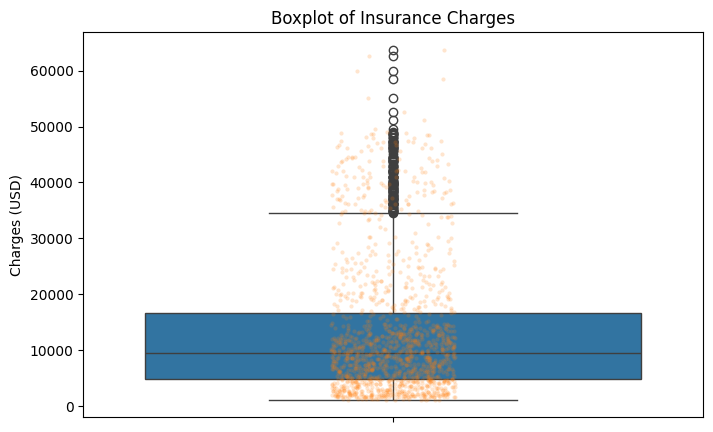

In [100]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['charges'])

sns.stripplot(
    y=df['charges'],
    alpha=0.2,
    size=3
)

plt.title('Boxplot of Insurance Charges')
plt.ylabel('Charges (USD)')

plt.show()

## Questão 5 – Código Python e Discursiva: Qualidade de Dados

In [101]:
# Código 3 Detecção e imputação de dados faltantes.
# Simulação de dados faltantes

np.random.seed(42)
idx_bmi = np.random.choice(df.index, size=40, replace=False)
idx_charges = np.random.choice(df.index, size=16, replace=False)

df.loc [idx_bmi, 'bmi'] = np.nan
df.loc [idx_charges, 'charges'] = np.nan

### Item a — Escreva o código para detectar e quantificar os valores nulos

In [102]:
print(df.isnull().sum())

age          0
sex          0
bmi         40
children     0
smoker       0
region       0
charges     16
dtype: int64


In [103]:
print(df[['bmi', 'charges']].isnull().sum())

bmi        40
charges    16
dtype: int64


### Item b — Impute os valores nulos de `bmi` com a MEDIANA da coluna

In [104]:
# Imputa BMI pela mediana
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

In [105]:
print(df[['bmi']].isnull().sum())

bmi    0
dtype: int64


### Item c — Impute os valores nulos de `charges` com a MEDIANA da coluna

In [106]:
# Imputa 'Charges' pela mediana
df['charges'] = df['charges'].fillna(df['charges'].median())

In [107]:
print(df[['charges']].isnull().sum())

charges    0
dtype: int64


### Item d

Na Questão 2 vimos:

* distribuição assimétrica à direita
* presença de outliers
* média > mediana

A média seria puxada pelos valores extremos.

**Resposta**

>Escolhemos a mediana porque a variável `charges` apresenta forte assimetria à direita e possui valores extremos elevados. Como a mediana é uma medida robusta, ela não é significativamente afetada pelos outliers e representa melhor o valor típico da distribuição. Utilizar a média poderia introduzir um viés para cima nos valores imputados.